# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

The dataset is related to 17 campaigns that ocurred between May 2008 and November 2010.

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

In [3]:
bank_campaings = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [4]:
bank_campaings.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [5]:
bank_campaings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [29]:
# Let's see the distribution of accepting the offer.
redable_success = bank_campaings[['y']].copy()
redable_success.rename(columns = {'y': 'Subscribed'}, inplace = True)
redable_success.value_counts(normalize=True)*100

,proportion
Subscribed,
no,88.734583
yes,11.265417


count    41188.00000
mean        40.02406
std         10.42125
min         17.00000
25%         32.00000
50%         38.00000
75%         47.00000
max         98.00000
Name: age, dtype: float64


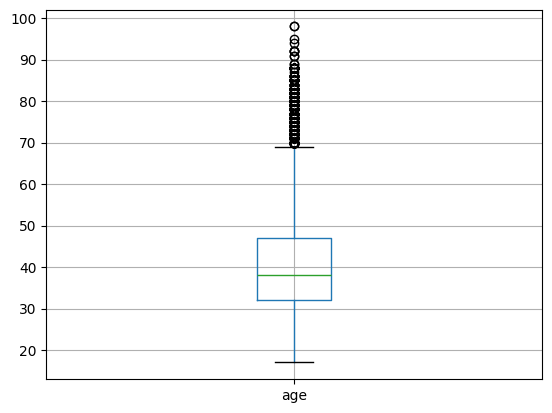

In [28]:
# Plotting the age column in a boxplot to visualize the age distribution
bank_campaings.boxplot(column = 'age')
print(bank_campaings['age'].describe())

In [27]:
# Grouping the data by job and calculating the acceptance rate of suscription to
# the long-term invesment, to see the distribution of job and accepting
# the offer
readable_job_subscribed = bank_campaings[['job', 'y']].copy()
readable_job_subscribed.rename(columns = {'y': 'Subscribed', 'job': 'Job'}, inplace = True)
job_mapping = {
    'admin.': 'Admin',
    'blue-collar': 'Blue-collar',
    'entrepreneur': 'Entrepreneur',
    'housemaid': 'Housemaid',
    'management': 'Management',
    'retired': 'Retired',
    'self-employed': 'Self-employed',
    'services': 'Services',
    'student': 'Student',
    'technician': 'Technician',
    'unemployed': 'Unemployed',
    'unknown': 'Unknown'
}
readable_job_subscribed['Job'] = readable_job_subscribed['Job'].replace(job_mapping)
readable_job_subscribed.groupby('Job')['Subscribed'].value_counts(normalize=True)*100

Job            Subscribed
Admin          no            87.027442
               yes           12.972558
Blue-collar    no            93.105684
               yes            6.894316
Entrepreneur   no            91.483516
               yes            8.516484
Housemaid      no            90.000000
               yes           10.000000
Management     no            88.782490
               yes           11.217510
Retired        no            74.767442
               yes           25.232558
Self-employed  no            89.514426
               yes           10.485574
Services       no            91.861930
               yes            8.138070
Student        no            68.571429
               yes           31.428571
Technician     no            89.173958
               yes           10.826042
Unemployed     no            85.798817
               yes           14.201183
Unknown        no            88.787879
               yes           11.212121
Name: proportion, dtype: float64

### Missing Values
Based on the result above, it seems none of the columns have missing values.

### Bias in response column
From the bank's data, 88.73% of the customers said no to the long term invesment offer. Only 11.27% said yes. This should be taken into account when training the models and adjusting the performance metrics.

### Coerce Features to a different data type
The pdays column is the number of days since the customer was last contacted. It says value '999' means the client has not been contacted in the past. This value would add noise to modeling. Instead, this column should be replaced with categorical buckets of days since last contacted and one of the buckets should be 'First' for first time being contacted.

As seen below, the data is heavily biased on '999'.

In [30]:
# Output a table of value_counts of pdays to better understand
# the distribution and decide on optimal buckets to analyze the data.
readable_pdays = bank_campaings[['pdays']].copy()
readable_pdays.rename(columns = {'pdays': 'Days since last contact'}, inplace = True)
readable_pdays['Days since last contact'].value_counts().sort_index()

,count
Days since last contact,
0,15
1,26
2,61
3,439
4,118
5,46
6,412
7,60
8,18


### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

Create a classifier model, exploring different techniques, to predict if a client will subscribe a long-term deposit. The model can help design a more efficient campaing that will make the best use of the bank's resources by targeting customers that are more likely to suscribe to a long-term deposit.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [31]:
# Let's remove the duration column since it says in the description
# it should be discarded for purposes of creating a predictive model.
bank_campaings.drop(columns = ['duration'], inplace = True)

# Let's replace the pdays column with a new column 'days_since_last_contact'
# with categories: 'New' for '999', '0 to 3', '4 to 6', '7 or more'.
bank_campaings['days_since_last_contact'] = 'New'
bank_campaings.loc[(bank_campaings['pdays'] >= 7) & (bank_campaings['pdays'] < 999), 'days_since_last_contact'] = '7 or more'
bank_campaings.loc[(bank_campaings['pdays'] >= 4) & (bank_campaings['pdays'] <= 6), 'days_since_last_contact'] = '4 to 6'
bank_campaings.loc[(bank_campaings['pdays'] >= 0) & (bank_campaings['pdays'] <= 3), 'days_since_last_contact'] = '0 to 3'
bank_campaings.drop(columns = ['pdays'], inplace = True)
bank_campaings['days_since_last_contact'].value_counts()

,count
days_since_last_contact,
New,39673
4 to 6,576
0 to 3,541
7 or more,398


In [32]:
# Separating the target column
X = bank_campaings.drop(columns = ['y'])
y = bank_campaings['y']

le = LabelEncoder()
y = le.fit_transform(y)

categorical_columns = X.select_dtypes(include=['object']).columns.tolist()
numerical_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(drop='first'), categorical_columns)
    ])

X_transformed = preprocessor.fit_transform(X)

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X_transformed, y, test_size=0.2, random_state=21)

### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [35]:
dummy_clf = DummyClassifier().fit(X_train, y_train)
baseline_score = dummy_clf.score(X_test, y_test)

print(f'Dummy Classifier Score: {baseline_score*100:.2f}%')

Dummy Classifier Score: 88.76%


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [36]:
log_reg = LogisticRegression(max_iter=1000).fit(X_train, y_train)

### Problem 9: Score the Model

What is the accuracy of your model?

In [37]:
log_reg_score = log_reg.score(X_test, y_test)

print(f'Logistic Regression Score: {log_reg_score*100:.2f}%')

Logistic Regression Score: 89.83%


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [40]:
models_default = {
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'SVM': SVC()
}

def format_time(seconds):
    minutes, seconds = divmod(seconds, 60)
    if minutes > 0:
      return f"{int(minutes)} minutes, {seconds:.2f} seconds"
    else:
      return f"{seconds:.3f} seconds"

results_default = []

for model_name, model in models_default.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time()
    train_time = end_time - start_time

    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    results_default.append({
        'Model': model_name,
        'Train Time': format_time(train_time),
        'Train Accuracy': f'{train_accuracy*100:.2f}%',
        'Test Accuracy': f'{test_accuracy*100:.2f}%'
    })

results_default_df = pd.DataFrame(results_default)
results_default_df.set_index('Model', inplace=True)
results_default_df

,Train Time,Train Accuracy,Test Accuracy
Model,,,
KNN,0.026 seconds,91.45%,89.14%
Decision Tree,1.556 seconds,99.56%,83.92%
SVM,"3 minutes, 48.58 seconds",90.57%,90.01%


### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [41]:
models = {
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [3, 5, 7, 11, 15, 21], 'weights': ['uniform', 'distance']}),
    'SVC': (SVC(), {'C': [0.1, 1, 10, 50, 100], 'kernel': ['linear', 'rbf']}),
    'Decision Tree': (DecisionTreeClassifier(), {'max_depth': [2, 5, 10, 20], 'min_samples_split': [2, 5, 10, 20]})
}

def grid_search(models, scoring=None):
  """
  Performs grid search on a dictionary of models and their corresponding parameter grids, allowing to also configure the strategy to evaluate the performance of the cross-validated model on the test set.

  Args:
    models: Dictionary with the model name as key and a tuple of the model and its parameter grid for hyperparameter tuning.
    scoring: Stategy to evaluate the cross-validated model on the test set.

  Returns:
    A list of dictionaries containing the results of the grid search. Each dictionary contains the following keys:
    - 'Model': The name of the model.
    - 'Train Time': The time it took to train the model.
    - 'Train Accuracy': The accuracy of the model on the training set.
    - 'Test Accuracy': The accuracy of the model on the test set.
    - 'best_params': The best parameters found by the grid search.
  """
  results = []
  for model_name, (model, param_grid) in models.items():
    grid_search = GridSearchCV(model, param_grid, cv=5, n_jobs=-1, scoring=scoring)
    start_time = time.time()
    grid_search.fit(X_train, y_train)
    end_time = time.time()
    train_time = end_time - start_time

    train_accuracy = grid_search.score(X_train, y_train)
    test_accuracy = grid_search.score(X_test, y_test)

    results.append({
        'Model': model_name,
        'Train Time': format_time(train_time),
        'Train Accuracy': f'{train_accuracy*100:.2f}%',
        'Test Accuracy': f'{test_accuracy*100:.2f}%',
        'best_params': grid_search.best_params_
    })

  return results

In [ ]:
# Grid Search with default scoring of the models.
# I'm expecting it to not perform as well since the default estimator does not
# consider an imbalanced Dataset.

results_default_scoring = grid_search(models)

# Extracting best params to be able to then output the table.
default_scoring_best_params = []
for result in results_default_scoring:
  default_scoring_best_params.append({'Model': result['Model'], 'best_params': result.pop('best_params')})

results_default_scoring_df = pd.DataFrame(results_default_scoring)
results_default_scoring_df.set_index('Model', inplace=True)
results_default_scoring_df

In [ ]:
# Grid Search with scoring set to 'f1'.
# This should perform better with an imbalanced Dataset.

results_f1_scoring = grid_search(models, scoring='f1')

# Extracting best params to be able to then output the table.
f1_scoring_best_params = []
for result in results_f1_scoring:
  f1_scoring_best_params.append({'Model': result['Model'], 'best_params': result.pop('best_params')})

results_f1_scoring_df = pd.DataFrame(results_f1_scoring)
results_f1_scoring_df.set_index('Model', inplace=True)
results_f1_scoring_df

In [ ]:
# Grid Search with scoring set to 'roc_auc'.
# This should perform better with an imbalanced Dataset. Let's see how it
# performs compared to 'f1'.

results_roc_auc_scoring = grid_search(models, scoring='roc_auc')

# Extracting best params to be able to then output the table.
roc_auc_scoring_best_params = []
for result in results_roc_auc_scoring:
  roc_auc_scoring_best_params.append({'Model': result['Model'], 'best_params': result.pop('best_params')})

results_roc_auc_scoring_df = pd.DataFrame(results_roc_auc_scoring)
results_roc_auc_scoring_df.set_index('Model', inplace=True)
results_roc_auc_scoring_df

In [ ]:
# Grid Search with scoring set to 'precision'.
# This should perform better with an imbalanced Dataset. Let's compare the
# model's performance compared to the models generated above.

results_precision_scoring = grid_search(models, scoring='precision')

# Extracting best params to be able to then output the table.
precision_scoring_best_params = []
for result in results_precision_scoring:
  precision_scoring_best_params.append({'Model': result['Model'], 'best_params': result.pop('best_params')})

results_precision_scoring_df = pd.DataFrame(results_precision_scoring)
results_precision_scoring_df.set_index('Model', inplace=True)
results_precision_scoring_df

##### Questions